# Disney Apriori Analysis (Revised)

This is the revised version of `Apriori_Analysis.ipynb`. Every code cell starts with a comment block that says **what changed and why**, using these tags:

| Tag | Meaning |
|---|---|
| `[KEPT]` | Same idea as your original notebook (sometimes cleaned up) |
| `[CHANGED]` | Your original logic, but fixed or generalized |
| `[ADDED]` | New step that was not in the original |
| `[REMOVED]` | Something from the original that is no longer here, and why |

**Summary of changes**

1. **One clean dataset** built from the two CSVs you actually have (`disney_movies_train.csv` + `disney_movies_test.csv`, 579 films). Only the films with a real multi-genre list are used as baskets.
2. **Apriori now grows until it stops by itself** (original stopped at k=3 by hand-coding; the lecture only stops at k=3 because its toy data runs out of itemsets). Your data has a frequent 4-itemset.
3. **Rules are generated for every frequent itemset**, using the lecture's "Candidates for Rules" restrictions (no empty sides, one-item consequent), then filtered by confidence and lift.
4. **Validation** (lecture "Evaluating Association Rules" slide): the provided train/test split and a cross-check against `mlxtend`.
5. **Cross-feature rules** (MPAA rating, era and gross level together with genres) to answer the professor's concern about depth.
6. **Visualizations** for the presentation.

In [1]:
# [CHANGED] Imports trimmed to what is actually used.
# [REMOVED] numpy, seaborn, KMeans, TransactionEncoder: they were imported but never used.
#           (KMeans is for clustering, which is not part of this Apriori notebook.)
# [ADDED]   mlxtend is now imported inside a try/except in the cross-check cell, only for validation.
import ast
from itertools import combinations
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)

In [2]:
# =====================  STEP 0: LOAD & CLEAN  =====================
# [FIXED] The two CSVs you have are NOT "disney_movies.csv" + "titles.csv".
#         They are one Disney dataset already split into train (463 rows) and test (116 rows).
#         Both have the same 6 columns: movie_title, release_date, genre, mpaa_rating,
#         total_gross, inflation_adjusted_gross. There is no imdb_score / runtime / release_year /
#         age_certification, so the old merge raised KeyError and everything below it never ran.
# [FIXED] The old cell also read the TEST file as "df_disney" and the TRAIN file as "df_titles".
DATA_DIR = "Datasets"          # change this if your CSVs live somewhere else
train_raw = pd.read_csv(f"{DATA_DIR}/disney_movies_train.csv")
test_raw = pd.read_csv(f"{DATA_DIR}/disney_movies_test.csv")
train_raw["split"] = "train"
test_raw["split"] = "test"
full = pd.concat([train_raw, test_raw], ignore_index=True)

# [FIXED] The genre column has two formats mixed together:
#           "['animation', 'comedy', 'family']"  -> real multi-genre list (the enriched films)
#           "Comedy", "Drama", NaN               -> one Disney label (or nothing)
#         A one-label film is not a real basket, and "Romantic Comedy" / "Thriller/Suspense" do not use
#         the same vocabulary as the lists. So Apriori uses only the rows with a list.
full["has_list"] = full["genre"].fillna("").str.startswith("[")

def parse_genres(g):
    p = ast.literal_eval(g)
    return sorted(set(str(x).lower().strip() for x in p))

merged = full[full["has_list"]].copy()
merged["genre_basket"] = merged["genre"].apply(parse_genres)
merged["disney_year"] = pd.to_datetime(merged["release_date"]).dt.year
merged = merged.reset_index(drop=True)

print(f"Rows in train + test            : {len(full)}")
print(f"Rows with a genre LIST (used)   : {len(merged)}   <- final dataset used everywhere")
print(f"Rows dropped (single/NaN genre) : {len(full) - len(merged)}")
print(merged["split"].value_counts().to_dict())
merged.drop(columns=["has_list"]).to_csv("disney_combined_clean.csv", index=False)


Rows in train + test            : 579
Rows with a genre LIST (used)   : 222   <- final dataset used everywhere
Rows dropped (single/NaN genre) : 357
{'train': 172, 'test': 50}


In [3]:
# =====================  APRIORI FUNCTIONS  =====================
# [ADDED] A reusable support() function. Original repeated the same sum(...) / N line everywhere.
def support(itemset, tx):
    s = set(itemset)
    return sum(1 for t in tx if s.issubset(t)) / len(tx)      # lecture slide: |{t in T : IS subset t}| / |T|

# [CHANGED] Original had three copy-pasted cells (k=1, k=2, k=3) and stopped at k=3.
#           This ONE function repeats "build candidates -> compute support -> keep/drop"
#           until no itemset survives. That is exactly the lecture's stopping rule:
#           "Repeat until no itemsets with minimal support are found / a threshold for k is reached".
#           It also returns a dictionary of ALL frequent itemsets and their supports,
#           so rule generation does not need to recount anything.
def apriori_manual(tx, minsupp, verbose=True):
    frequent = {}                                   # frozenset(itemset) -> support
    all_items = sorted({i for t in tx for i in t})

    # ---- k = 1 ----  [KEPT] same logic as original Step 1
    rows, Lk = [], []
    for item in all_items:
        s = support({item}, tx)
        keep = s >= minsupp
        rows.append({"Itemset": "{" + item + "}", "Support": round(s, 3), "Status": "Keep" if keep else "Drop"})
        if keep:
            frequent[frozenset([item])] = s
            Lk.append(frozenset([item]))
    if verbose:
        print("=== Table k=1 ===");  print(pd.DataFrame(rows).to_string(index=False))

    # ---- k >= 2 ----
    k = 2
    while Lk:
        prev = set(Lk)
        items = sorted(set().union(*Lk))
        # [KEPT] Apriori property (original Step 3): a candidate is only built if ALL its (k-1)-subsets are frequent.
        # [CHANGED] Now applied at every k, not just k=3.
        cands = [frozenset(c) for c in combinations(items, k)
                 if all(frozenset(sub) in prev for sub in combinations(c, k - 1))]
        if not cands:
            if verbose:
                print(f"\nNo candidates for k={k} -> growing terminates.")
            break
        rows, Lk = [], []
        for c in cands:
            s = support(c, tx)
            keep = s >= minsupp
            rows.append({"Itemset": "{" + ", ".join(sorted(c)) + "}", "Support": round(s, 3), "Status": "Keep" if keep else "Drop"})
            if keep:
                frequent[c] = s
                Lk.append(c)
        if verbose:
            print(f"\n=== Table k={k} ===");  print(pd.DataFrame(rows).to_string(index=False))
        if not Lk:
            if verbose:
                print(f"\nNo itemset at k={k} reached minsupp -> growing terminates.")
            break
        k += 1
    return frequent

In [4]:
# =====================  TRANSACTIONS  =====================
# [CHANGED] Original built `transactions` from a second merge. Now it comes from the same clean dataset.
# [CHANGED] Each basket is a Python set (faster and simpler for the subset checks below).
transactions = [set(b) for b in merged["genre_basket"]]
items = sorted({i for t in transactions for i in t})
N = len(transactions)
minsupp = 0.15
print(f"|T| = {N} transactions, |I| = {len(items)} items")
for t in transactions[:5]:
    print(sorted(t))

print("Number of transactions (films):", N)
print("Average genres per film       :", round(sum(len(t) for t in transactions) / N, 2))

|T| = 222 transactions, |I| = 18 items
['documentation', 'family']
['animation', 'comedy', 'drama', 'family', 'fantasy', 'scifi']
['action', 'animation', 'family']
['drama', 'family', 'sport']
['action', 'fantasy', 'scifi']
Number of transactions (films): 222
Average genres per film       : 3.71


In [5]:
# =====================  RUN APRIORI ON GENRES  =====================
# [CHANGED] Replaces original cells "Step 1", "Step 2", "Step 3" (k=1,2,3).
#           The k=1..3 tables should match your old ones (apart from small changes caused by the cleaner merge).
#           NEW: a k=4 table appears because {animation, comedy, family, fantasy} has all four of its
#           3-item subsets frequent, so Apriori MUST test it.
for ms in [0.05, 0.10, 0.15, 0.20, 0.30]:
    f = apriori_manual(transactions, ms, verbose=False)
    print(f"minsupp={ms:.2f} -> {len(f):3d} frequent itemsets, largest size k={max(len(s) for s in f)}")
    
frequent = apriori_manual(transactions, minsupp)

minsupp=0.05 ->  79 frequent itemsets, largest size k=5
minsupp=0.10 ->  32 frequent itemsets, largest size k=4
minsupp=0.15 ->  24 frequent itemsets, largest size k=4
minsupp=0.20 ->  17 frequent itemsets, largest size k=3
minsupp=0.30 ->   8 frequent itemsets, largest size k=2
=== Table k=1 ===
        Itemset  Support Status
       {action}    0.252   Keep
    {animation}    0.365   Keep
       {comedy}    0.658   Keep
        {crime}    0.072   Drop
{documentation}    0.059   Drop
        {drama}    0.365   Keep
     {european}    0.068   Drop
       {family}    0.802   Keep
      {fantasy}    0.396   Keep
      {history}    0.036   Drop
       {horror}    0.023   Drop
        {music}    0.059   Drop
      {romance}    0.185   Keep
        {scifi}    0.180   Keep
        {sport}    0.099   Drop
     {thriller}    0.050   Drop
          {war}    0.014   Drop
      {western}    0.027   Drop

=== Table k=2 ===
             Itemset  Support Status
 {action, animation}    0.063   Drop
 

In [6]:
multi = sorted((s for s in frequent if len(s) >= 2), key=lambda s: (len(s), sorted(s)))
for s in multi:
    print(sorted(s), round(frequent[s], 3))

['action', 'family'] 0.18
['animation', 'comedy'] 0.284
['animation', 'family'] 0.365
['animation', 'fantasy'] 0.243
['comedy', 'drama'] 0.212
['comedy', 'family'] 0.59
['comedy', 'fantasy'] 0.297
['drama', 'family'] 0.275
['family', 'fantasy'] 0.369
['family', 'romance'] 0.153
['animation', 'comedy', 'family'] 0.284
['animation', 'comedy', 'fantasy'] 0.198
['animation', 'family', 'fantasy'] 0.243
['comedy', 'drama', 'family'] 0.185
['comedy', 'family', 'fantasy'] 0.284
['animation', 'comedy', 'family', 'fantasy'] 0.198


In [7]:
# =====================  STEP 4: CANDIDATES FOR RULES  =====================
def rule_candidates(target, tx):
    items = sorted(target)
    s_xy = support(items, tx)
    rows = []
    for r in range(0, len(items) + 1):
        for ante in combinations(items, r):
            ante = set(ante); cons = set(items) - ante
            s_x, s_y = support(ante, tx), support(cons, tx)
            rows.append({
                "Rule": ("{" + ", ".join(sorted(ante)) + "}" if ante else "Ø") + " => " +
                        ("{" + ", ".join(sorted(cons)) + "}" if cons else "Ø"),
                "Confidence": round(s_xy / s_x, 2),
                "Lift": round(s_xy / (s_x * s_y), 2),
                "Leverage": round(s_xy - s_x * s_y, 2),
                "Kept?": "Yes" if ante and len(cons) == 1 else "No"})
    return pd.DataFrame(rows)

print(rule_candidates({"animation", "comedy", "family", "fantasy"}, transactions).to_string(index=False))

                                     Rule  Confidence  Lift  Leverage Kept?
Ø => {animation, comedy, family, fantasy}        0.20  1.00      0.00    No
 {animation} => {comedy, family, fantasy}        0.54  1.91      0.09    No
 {comedy} => {animation, family, fantasy}        0.30  1.24      0.04    No
 {family} => {animation, comedy, fantasy}        0.25  1.25      0.04    No
 {fantasy} => {animation, comedy, family}        0.50  1.76      0.09    No
 {animation, comedy} => {family, fantasy}        0.70  1.89      0.09    No
 {animation, family} => {comedy, fantasy}        0.54  1.83      0.09    No
 {animation, fantasy} => {comedy, family}        0.81  1.38      0.05    No
 {comedy, family} => {animation, fantasy}        0.34  1.38      0.05    No
 {comedy, fantasy} => {animation, family}        0.67  1.83      0.09    No
 {family, fantasy} => {animation, comedy}        0.54  1.89      0.09    No
 {animation, comedy, family} => {fantasy}        0.70  1.76      0.09   Yes
 {animation,

In [8]:
# =====================  RULES FOR ALL FREQUENT ITEMSETS  =====================
# [CHANGED] Original generated rules for ONE itemset only. Now: every frequent itemset with 2+ items.
# [ADDED]   Lecture slide "Candidates for Rules": usually (1) no empty antecedent/consequent, (2) only ONE item as consequent.
#           The 8-rule table above is for learning; the table below is what you report as findings.
def generate_rules(frequent, single_consequent=True):
    rows = []
    for itemset, s_xy in frequent.items():
        if len(itemset) < 2:
            continue
        for r in range(1, len(itemset)):                       # r >= 1 and r < n  -> no empty sides
            for ante in combinations(sorted(itemset), r):
                ante = frozenset(ante); cons = itemset - ante
                if single_consequent and len(cons) != 1:
                    continue
                # Apriori property guarantees ante and cons are frequent, so their support is already stored.
                s_x, s_y = frequent[ante], frequent[cons]
                rows.append({
                    "antecedent": ante, "consequent": cons,
                    "Rule": "{" + ", ".join(sorted(ante)) + "} => {" + ", ".join(sorted(cons)) + "}",
                    "Support": s_xy,
                    "Confidence": s_xy / s_x,                  # support(X u Y) / support(X)
                    "Lift": s_xy / (s_x * s_y),                # support(X u Y) / (support(X) * support(Y))
                    "Leverage": s_xy - s_x * s_y})             # support(X u Y) - support(X) * support(Y)
    return pd.DataFrame(rows).sort_values("Lift", ascending=False).reset_index(drop=True)

MIN_CONF, MIN_LIFT = 0.6, 1.2          # [ADDED] thresholds suggested in your Gemini/professor pipeline
all_rules = generate_rules(frequent)
rules_f = all_rules[(all_rules["Confidence"] >= MIN_CONF) & (all_rules["Lift"] >= MIN_LIFT)].reset_index(drop=True)

print(f"Rules generated: {len(all_rules)}   |   after filter (conf >= {MIN_CONF}, lift >= {MIN_LIFT}): {len(rules_f)}")
show = ["Rule", "Support", "Confidence", "Lift", "Leverage"]
print(rules_f[show].round(3).to_string(index=False))

all_rules["Ends in family"] = all_rules["consequent"].apply(lambda c: "family" in c)
rules_f = all_rules[(all_rules["Confidence"] >= MIN_CONF) & (all_rules["Lift"] >= MIN_LIFT)].reset_index(drop=True)
print(rules_f[["Rule", "Support", "Confidence", "Lift", "Leverage", "Ends in family"]].round(3).to_string(index=False))

Rules generated: 39   |   after filter (conf >= 0.6, lift >= 1.2): 14
                                    Rule  Support  Confidence  Lift  Leverage
{comedy, family, fantasy} => {animation}    0.198       0.698 1.914     0.095
        {comedy, fantasy} => {animation}    0.198       0.667 1.827     0.090
        {family, fantasy} => {animation}    0.243       0.659 1.805     0.108
        {animation, comedy} => {fantasy}    0.198       0.698 1.762     0.086
{animation, comedy, family} => {fantasy}    0.198       0.698 1.762     0.086
                {fantasy} => {animation}    0.243       0.614 1.682     0.099
                {animation} => {fantasy}    0.243       0.667 1.682     0.099
        {animation, family} => {fantasy}    0.243       0.667 1.682     0.099
{animation, comedy, fantasy} => {family}    0.198       1.000 1.247     0.039
        {animation, fantasy} => {family}    0.243       1.000 1.247     0.048
                 {animation} => {family}    0.365       1.000 1.247     

In [9]:
# =====================  VALIDATION (lecture: "Evaluating Association Rules")  =====================
train_df = merged[merged["split"] == "train"]
test_df = merged[merged["split"] == "test"]
train_tx = [set(b) for b in train_df["genre_basket"]]
test_tx = [set(b) for b in test_df["genre_basket"]]

print(f"Train films: {len(train_tx)} | Test films: {len(test_tx)}")

rules_tr = generate_rules(apriori_manual(train_tx, minsupp, verbose=False))
rules_tr = rules_tr[(rules_tr["Confidence"] >= MIN_CONF) & (rules_tr["Lift"] >= MIN_LIFT)].copy()

def eval_rule(ante, cons, tx):
    s_x, s_y, s_xy = support(ante, tx), support(cons, tx), support(ante | cons, tx)
    conf = s_xy / s_x if s_x > 0 else float("nan")
    lift = s_xy / (s_x * s_y) if s_x > 0 and s_y > 0 else float("nan")
    return conf, lift

rules_tr[["Test conf", "Test lift"]] = rules_tr.apply(
    lambda r: pd.Series(eval_rule(r["antecedent"], r["consequent"], test_tx)), axis=1
)
rules_tr["Holds on test?"] = ((rules_tr["Test conf"] >= MIN_CONF) & (rules_tr["Test lift"] > 1)).map({True: "Yes", False: "No"})

show_cols = ["Rule", "Support", "Confidence", "Lift", "Leverage", "Test conf", "Test lift", "Holds on test?"]
print(rules_tr[show_cols].round(2).to_string(index=False))

print("\nWhat do the similarities/differences indicate?")
print("If rules match across splits, they represent stable patterns. If they differ significantly, they are likely coincidental artifacts of a specific sample.")

Train films: 172 | Test films: 50
                                    Rule  Support  Confidence  Lift  Leverage  Test conf  Test lift Holds on test?
{comedy, family, fantasy} => {animation}     0.18        0.72  1.91      0.09       0.65       2.03            Yes
        {comedy, fantasy} => {animation}     0.18        0.67  1.78      0.08       0.65       2.03            Yes
        {family, fantasy} => {animation}     0.23        0.66  1.75      0.10       0.65       2.04            Yes
        {animation, comedy} => {fantasy}     0.18        0.63  1.70      0.07       0.93       1.93            Yes
{animation, comedy, family} => {fantasy}     0.18        0.63  1.70      0.07       0.93       1.93            Yes
                {fantasy} => {animation}     0.23        0.61  1.61      0.09       0.62       1.95            Yes
                {animation} => {fantasy}     0.23        0.60  1.61      0.09       0.94       1.95            Yes
        {animation, family} => {fantasy}     0

In [10]:
# =====================  CROSS-CHECK WITH mlxtend  =====================
# [ADDED] You imported mlxtend in the original notebook but never used it.
#         Use it as an independent check that your manual Apriori is correct.
#         If both give the same itemsets and supports, you can say so in your presentation.
try:
    from mlxtend.frequent_patterns import apriori as mlx_apriori
    all_items = sorted({i for t in transactions for i in t})
    onehot = pd.DataFrame([[item in t for item in all_items] for t in transactions], columns=all_items)
    fi = mlx_apriori(onehot, min_support=minsupp, use_colnames=True)
    mlx = {frozenset(row.itemsets): row.support for row in fi.itertuples()}
    same_sets = set(mlx) == set(frequent)
    max_diff = max(abs(mlx[k] - frequent[k]) for k in frequent) if same_sets else None
    print("Same as mlxtend:", same_sets)
    print("Max support difference            :", max_diff)
    print("Manual:", len(frequent), "itemsets | mlxtend:", len(mlx), "itemsets")
except ImportError:
    print("mlxtend not installed. Run:  pip install mlxtend   then re-run this cell.")

Same as mlxtend: True
Max support difference            : 0.0
Manual: 24 itemsets | mlxtend: 24 itemsets


In [11]:
# =====================  CROSS-FEATURE RULES  =====================
#         It now uses what IS there: mpaa_rating, release decade, and a gross level.
#         Prefixes (genre:, rating:, era:, gross:) stop different features from clashing.
# NOTE: continuous columns have to be binned. Here we use a simple median split (high = at or above the median).
med_gross = merged["inflation_adjusted_gross"].median()

def make_basket(row):
    items = [f"genre:{g}" for g in row["genre_basket"]]
    if pd.notna(row["mpaa_rating"]):
        items.append(f"rating:{row['mpaa_rating']}")
    items.append(f"era:{(row['disney_year'] // 10) * 10}s")
    items.append("gross:high" if row["inflation_adjusted_gross"] >= med_gross else "gross:low")
    return set(items)

tx_x = [make_basket(r) for _, r in merged.iterrows()]
minsupp_x = 0.10          # lower than 0.15 because there are many more distinct items now
freq_x = apriori_manual(tx_x, minsupp_x, verbose=False)
print(f"Frequent itemsets with cross-feature baskets (minsupp={minsupp_x}): {len(freq_x)}")

targets = {"gross:high", "gross:low"}
rules_x = generate_rules(freq_x)
rules_x = rules_x[rules_x["consequent"].apply(lambda c: next(iter(c)) in targets)]
rules_x = rules_x[(rules_x["Confidence"] >= MIN_CONF) & (rules_x["Lift"] >= MIN_LIFT)].reset_index(drop=True)
print(f"Rules predicting gross level (conf >= {MIN_CONF}, lift >= {MIN_LIFT}): {len(rules_x)}")
print(rules_x[["Rule", "Support", "Confidence", "Lift", "Leverage"]].head(15).round(3).to_string(index=False))


Frequent itemsets with cross-feature baskets (minsupp=0.1): 171
Rules predicting gross level (conf >= 0.6, lift >= 1.2): 30
                                                                        Rule  Support  Confidence  Lift  Leverage
                     {genre:family, genre:fantasy, rating:G} => {gross:high}    0.113       0.806 1.613     0.043
                                   {genre:fantasy, rating:G} => {gross:high}    0.113       0.806 1.613     0.043
{genre:animation, genre:comedy, genre:family, genre:fantasy} => {gross:high}    0.158       0.795 1.591     0.059
              {genre:animation, genre:comedy, genre:fantasy} => {gross:high}    0.158       0.795 1.591     0.059
              {genre:animation, genre:family, genre:fantasy} => {gross:high}    0.185       0.759 1.519     0.063
                            {genre:animation, genre:fantasy} => {gross:high}    0.185       0.759 1.519     0.063
                         {era:1990s, genre:family, rating:PG} => {gross:low}  

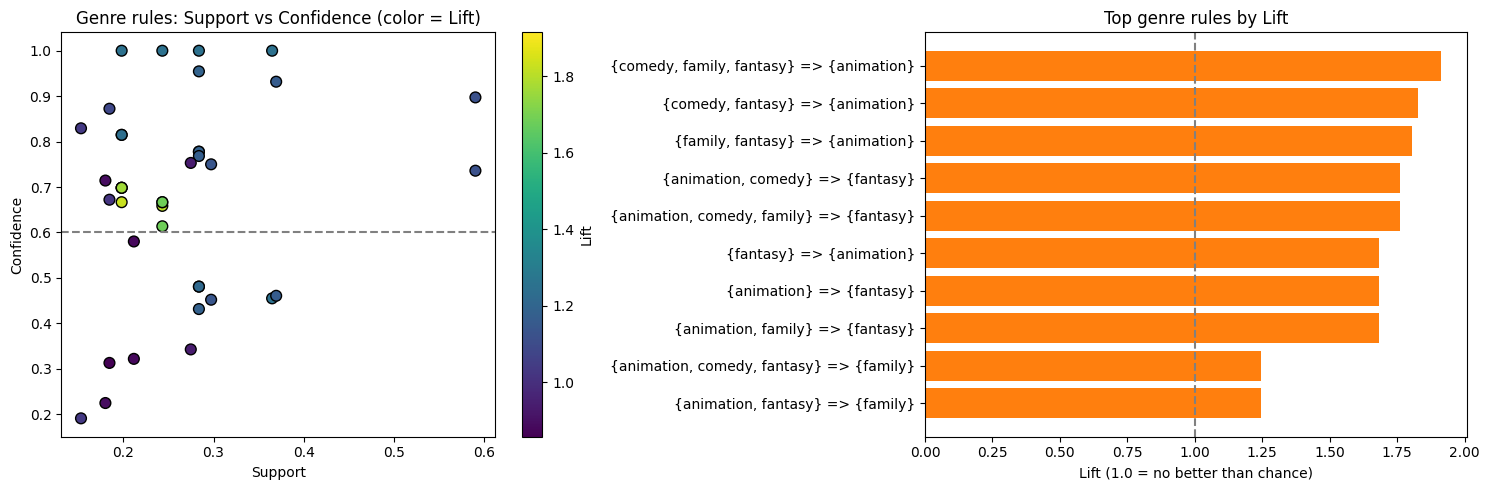

In [12]:
# =====================  VISUALIZATIONS  =====================
# [ADDED] Your original notebook had no charts. The grading rubric gives 15% for visualization.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (1) Support vs Confidence, colored by Lift (all genre rules before filtering)
sc = axes[0].scatter(all_rules["Support"], all_rules["Confidence"], c=all_rules["Lift"], cmap="viridis", s=60, edgecolor="k")
axes[0].axhline(MIN_CONF, ls="--", c="gray")
axes[0].set_xlabel("Support"); axes[0].set_ylabel("Confidence"); axes[0].set_title("Genre rules: Support vs Confidence (color = Lift)")
fig.colorbar(sc, ax=axes[0], label="Lift")

# (2) Top rules by Lift
top = rules_f.head(10).iloc[::-1]
axes[1].barh(top["Rule"], top["Lift"], color="tab:orange")
axes[1].axvline(1.0, ls="--", c="gray")
axes[1].set_xlabel("Lift (1.0 = no better than chance)"); axes[1].set_title("Top genre rules by Lift")
plt.tight_layout()
plt.show()

## Talking points and caveats for your presentation

- **Why only the list rows:** films with a genre list average about 3.7 genres, so each one is a real basket. The other rows have a single label.
- **Apriori stops by itself:** k=1 -> k=2 -> k=3 -> k=4 -> no more candidates.
- **Lift and leverage over confidence:** `{family}` is in most films, so rules ending in family look confident but add nothing beyond chance.
- **Selection bias:** only 222 of the 579 films have a genre list, so your rules describe *those* films, not all Disney films.
- **Genre tags are noisy** (for example, a classic fairy tale tagged thriller), so treat the rules as patterns in the labels.
- **Regression is not in this notebook.** `disney_combined_clean.csv` is saved for it (no IMDb columns in these CSVs, so gross is the only numeric target).